# Import Libraries

In [23]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

# Display settings
pd.set_option("display.max_columns", None)
pd.set_option("display.max_rows", 100)

print("Libraries imported successfully.")

Libraries imported successfully.


# Load CSV

In [24]:
file_path = "Dataset/Crimes_-_One_year_prior_to_present_20260831.csv"

df = pd.read_csv(file_path)

print("Dataset loaded successfully!")

Dataset loaded successfully!


# Basic Data Information

In [25]:
print("Number of rows:", df.shape[0])
print("Number of columns:", df.shape[1])

print("\nColumn names:")
for i, column in enumerate(df.columns, start=1):
    print(f"{i}. {column}")

Number of rows: 229275
Number of columns: 17

Column names:
1. CASE#
2. DATE OF OCCURRENCE
3. BLOCK
4.  IUCR
5. PRIMARY DESCRIPTION
6. SECONDARY DESCRIPTION
7. LOCATION DESCRIPTION
8. ARREST
9. DOMESTIC
10. BEAT
11. WARD
12. FBI CD
13. X COORDINATE
14. Y COORDINATE
15. LATITUDE
16. LONGITUDE
17. LOCATION


# First 5 Records

In [26]:
df.head()

,CASE#,DATE OF OCCURRENCE,BLOCK,IUCR,PRIMARY DESCRIPTION,SECONDARY DESCRIPTION,LOCATION DESCRIPTION,ARREST,DOMESTIC,BEAT,WARD,FBI CD,X COORDINATE,Y COORDINATE,LATITUDE,LONGITUDE,LOCATION
0,JJ387233,08/24/2025 05:03:00 AM,029XX W 25TH PL,0486,BATTERY,DOMESTIC BATTERY SIMPLE,RESIDENCE,Y,Y,1033,24.0,08B,1157153.0,1886939.0,41.845527,-87.698757,"(41.845527098, -87.698756503)"
1,JJ387253,08/24/2025 05:25:00 AM,070XX S JEFFERY BLVD,0460,BATTERY,SIMPLE,STREET,N,N,331,5.0,08B,1190765.0,1858575.0,41.766947,-87.576322,"(41.766946791, -87.57632241)"
2,JJ387811,08/24/2025 05:30:00 AM,102XX S OAKLEY AVE,0620,BURGLARY,UNLAWFUL ENTRY,RESIDENCE - GARAGE,N,N,2213,19.0,05,1162636.0,1836625.0,41.707346,-87.680037,"(41.707345681, -87.680037133)"
3,JJ387309,08/24/2025 05:30:00 AM,027XX N CALIFORNIA AVE,0760,BURGLARY,BURGLARY FROM MOTOR VEHICLE,PARKING LOT / GARAGE (NON RESIDENTIAL),N,N,1411,1.0,06,1157241.0,1918050.0,41.930897,-87.697588,"(41.930896787, -87.697587655)"
4,JJ387926,08/24/2025 05:32:00 AM,028XX W 55TH ST,1310,CRIMINAL DAMAGE,TO PROPERTY,SMALL RETAIL STORE,N,N,824,15.0,14,1158561.0,1868058.0,41.793687,-87.694105,"(41.793686636, -87.694104755)"


# Data types

In [27]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 229275 entries, 0 to 229274
Data columns (total 17 columns):
 #   Column                 Non-Null Count   Dtype  
---  ------                 --------------   -----  
 0   CASE#                  229275 non-null  object 
 1   DATE OF OCCURRENCE     229275 non-null  object 
 2   BLOCK                  229275 non-null  object 
 3    IUCR                  229275 non-null  object 
 4   PRIMARY DESCRIPTION    229275 non-null  object 
 5   SECONDARY DESCRIPTION  229275 non-null  object 
 6   LOCATION DESCRIPTION   228238 non-null  object 
 7   ARREST                 229275 non-null  object 
 8   DOMESTIC               229275 non-null  object 
 9   BEAT                   229275 non-null  int64  
 10  WARD                   229274 non-null  float64
 11  FBI CD                 229275 non-null  object 
 12  X COORDINATE           229235 non-null  float64
 13  Y COORDINATE           229235 non-null  float64
 14  LATITUDE               229235 non-nu

# Missing Values

In [28]:
missing_values = df.isnull().sum()

missing_percentage = (df.isnull().sum() / len(df)) * 100

missing_summary = pd.DataFrame({
    "Missing Count": missing_values,
    "Missing Percentage": missing_percentage.round(2)
})

missing_summary = missing_summary.sort_values(
    by="Missing Count",
    ascending=False
)

missing_summary

,Missing Count,Missing Percentage
LOCATION DESCRIPTION,1037,0.45
LOCATION,40,0.02
LONGITUDE,40,0.02
LATITUDE,40,0.02
Y COORDINATE,40,0.02
X COORDINATE,40,0.02
WARD,1,0.00
BEAT,0,0.00
FBI CD,0,0.00
CASE#,0,0.00


# Duplicate Records

In [29]:
duplicate_count = df.duplicated().sum()

print("Number of duplicate rows:", duplicate_count)

Number of duplicate rows: 2


# Data Range

In [30]:
print(df["DATE OF OCCURRENCE"].head())

dates = pd.to_datetime(
    df["DATE OF OCCURRENCE"],
    errors="coerce"
)

print("Earliest crime date:", dates.min())
print("Latest crime date:", dates.max())

0    08/24/2025 05:03:00 AM
1    08/24/2025 05:25:00 AM
2    08/24/2025 05:30:00 AM
3    08/24/2025 05:30:00 AM
4    08/24/2025 05:32:00 AM
Name: DATE OF OCCURRENCE, dtype: object
Earliest crime date: 2025-08-24 05:03:00
Latest crime date: 2026-08-23 00:00:00


# Crime Category

In [31]:
crime_counts = df["PRIMARY DESCRIPTION"].value_counts()

print("Number of unique crime categories:",
      df["PRIMARY DESCRIPTION"].nunique())

crime_counts.head(20)

Number of unique crime categories: 31


PRIMARY DESCRIPTION
THEFT                               49978
BATTERY                             42191
CRIMINAL DAMAGE                     25530
ASSAULT                             20737
MOTOR VEHICLE THEFT                 18127
OTHER OFFENSE                       15662
DECEPTIVE PRACTICE                  13276
BURGLARY                            12922
NARCOTICS                            6498
CRIMINAL TRESPASS                    5509
WEAPONS VIOLATION                    4929
ROBBERY                              4847
CRIMINAL SEXUAL ASSAULT              1635
OFFENSE INVOLVING CHILDREN           1467
SEX OFFENSE                          1343
PUBLIC PEACE VIOLATION               1184
INTERFERENCE WITH PUBLIC OFFICER      968
STALKING                              631
HOMICIDE                              445
ARSON                                 357
Name: count, dtype: int64

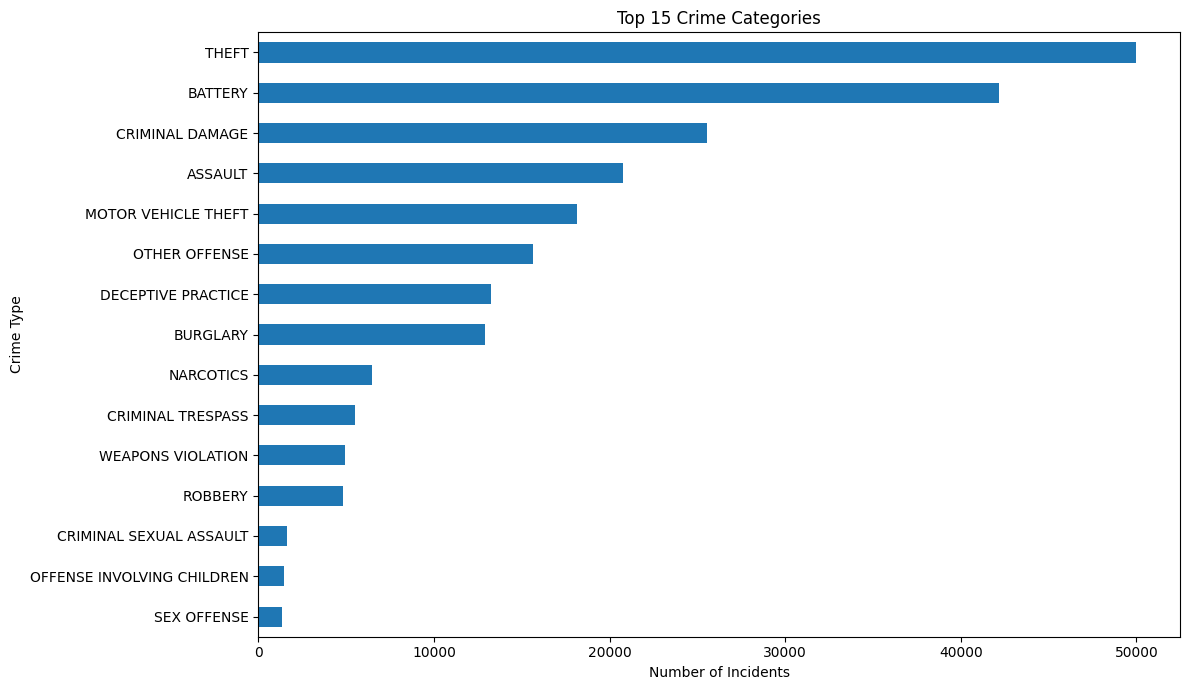

In [32]:
plt.figure(figsize=(12, 7))

crime_counts.head(15).sort_values().plot(kind="barh")

plt.title("Top 15 Crime Categories")
plt.xlabel("Number of Incidents")
plt.ylabel("Crime Type")
plt.tight_layout()
plt.show()

# Coordinate Inspection

In [33]:
print("Latitude statistics:")
print(df["LATITUDE"].describe())

print("\nLongitude statistics:")
print(df["LONGITUDE"].describe())

Latitude statistics:
count    229235.000000
mean         41.845845
std           0.086014
min          41.644590
25%          41.772070
50%          41.863632
75%          41.908423
max          42.022548
Name: LATITUDE, dtype: float64

Longitude statistics:
count    229235.000000
mean        -87.667439
std           0.059065
min         -87.928903
25%         -87.708321
50%         -87.660094
75%         -87.626214
max         -87.524529
Name: LONGITUDE, dtype: float64


In [34]:
print("Missing latitude:",
      df["LATITUDE"].isna().sum())

print("Missing longitude:",
      df["LONGITUDE"].isna().sum())

Missing latitude: 40
Missing longitude: 40


In [35]:
print("\nSample coordinates:")
print(df[["LATITUDE", "LONGITUDE"]].head(10))


Sample coordinates:
    LATITUDE  LONGITUDE
0  41.845527 -87.698757
1  41.766947 -87.576322
2  41.707346 -87.680037
3  41.930897 -87.697588
4  41.793687 -87.694105
5  41.773085 -87.568335
6  41.808899 -87.643515
7  41.833364 -87.617008
8  41.747758 -87.652451
9  41.909664 -87.742729
